# Deep Learning Lab — Assignment 8
## Neural Language Translation: Attention Networks, Self-Attention and Multi-Head Attention

In [1]:
# ── Global seed (DO NOT MOVE OR CHANGE) ──────────────────────────────────────
import random, numpy as np, torch
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

import re, math
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cuda


In [2]:
PAD_IDX = 0
SOS_IDX = 1
EOS_IDX = 2
UNK_IDX = 3
MAX_LEN = 30
SRC_COL = 0
TGT_COL = 1
BATCH_SIZE = 64

---
## Task 1: Data Preparation

In [3]:
# Task 1 — YOUR CODE HERE
df_train = pd.read_csv("train.tsv", delimiter='\t', header=None)
df_val = pd.read_csv("val.tsv", delimiter='\t', header=None)
df_test = pd.read_csv("test.tsv", delimiter='\t', header=None)
df_train.head()

,0,1
0,"Two young, White males are outside near many b...",Zwei junge weiße Männer sind im Freien in der ...
1,Several men in hard hats are operating a giant...,Mehrere Männer mit Schutzhelmen bedienen ein A...
2,A little girl climbing into a wooden playhouse.,Ein kleines Mädchen klettert in ein Spielhaus ...
3,A man in a blue shirt is standing on a ladder ...,Ein Mann in einem blauen Hemd steht auf einer ...
4,Two men are at the stove preparing food.,Zwei Männer stehen am Herd und bereiten Essen zu.


In [4]:
len(df_train), len(df_val), len(df_test)

(29000, 1014, 1000)

In [5]:
def clean_and_tokenize(text):
    text = text.lower()
    return re.findall(f"[a-z0-9]+|[.,!?]", text)

In [6]:
clean_and_tokenize("Two young, White males are outside near many bushes.")

['two',
 'young',
 ',',
 'white',
 'males',
 'are',
 'outside',
 'near',
 'many',
 'bushes',
 '.']

In [7]:
df_train[0].values

array(['Two young, White males are outside near many bushes.',
       'Several men in hard hats are operating a giant pulley system.',
       'A little girl climbing into a wooden playhouse.', ...,
       "Two male construction workers are working on a street outside someone's home",
       'An elderly man sits outside a storefront accompanied by a young boy with a cart.',
       'A man in shorts and a Hawaiian shirt leans over the rail of a pilot boat, with fog and mountains in the background.'],
      dtype=object)

In [66]:
class Vocab:
    def __init__(self, texts):
        c = Counter()
        for t in texts:
            c.update(clean_and_tokenize(t))
        self.stoi = {"<pad>": PAD_IDX, "<sos>": SOS_IDX, "<eos>": EOS_IDX, "<unk>": UNK_IDX}
        count = len(self.stoi)
        self.itos = {PAD_IDX: "<pad>", SOS_IDX: "<sos>", EOS_IDX: "<eos>", UNK_IDX: "<unk>"}
        for word, _ in sorted(c.items(), key=lambda item: (-item[1], item[0])):
            self.stoi[word] = count
            self.itos[count] = word
            count += 1
    def __len__(self):
        return len(self.stoi)
    def encode(self, text):
        return [self.stoi.get(t, UNK_IDX) for t in clean_and_tokenize(text)]
    def decode(self, ids):
        out = []
        for i in ids:
            tok = self.itos[int(i)]
            if tok == "<eos>":
                break
            if tok not in ("<pad>", "<sos>"):
                out.append(tok)
        return " ".join(out)
    def decode_numbers(self, ids):
        return [self.itos[int(i)] for i in ids]

In [67]:
src_vocab = Vocab(df_train[SRC_COL].values)
tgt_vocab = Vocab(df_train[TGT_COL].values)
len(src_vocab), len(tgt_vocab)

(9770, 17243)

In [10]:
class TranlationDataset(torch.utils.data.Dataset):
    def __init__(self, frame, src_vocab, tgt_vocab):
        # print("init")
        self.frame = frame.reset_index(drop=True)
        self.src_vocab = src_vocab
        self.tgt_vocab = tgt_vocab
    def __len__(self):
        # print("len")
        return len(self.frame)
    def __getitem__(self, index):
        # print("getitem")
        r = self.frame.iloc[index]
        src_list = [self.src_vocab.stoi["<sos>"]] + self.src_vocab.encode(r[SRC_COL])[:MAX_LEN-2] + [self.src_vocab.stoi["<eos>"]]
        src_len = len(src_list)
        src_mask = [1] * src_len + [0] * (MAX_LEN - src_len)
        src_list += [self.src_vocab.stoi["<pad>"]] * (MAX_LEN - src_len)
        src = torch.tensor(
            src_list,
            dtype=torch.long
        )
        src_mask = torch.tensor(src_mask, dtype=torch.bool)
        tgt_list = [self.tgt_vocab.stoi["<sos>"]] + self.tgt_vocab.encode(r[TGT_COL])[:MAX_LEN-2] + [self.tgt_vocab.stoi["<eos>"]]
        tgt_len = len(tgt_list)
        tgt_list += [self.tgt_vocab.stoi["<pad>"]] * (MAX_LEN - tgt_len)
        tgt = torch.tensor(
            tgt_list,
            dtype=torch.long
        )
        # print(src)
        # print(tgt)
        return src, tgt, src_mask

In [11]:
data_generator = TranlationDataset(df_test, src_vocab, tgt_vocab)
# printing for T01
original_sentence = df_test.iloc[0][SRC_COL]
tokens = clean_and_tokenize(original_sentence)
numericalised_sequence = src_vocab.encode(original_sentence)
src_tensor, _, padding_mask = data_generator.__getitem__(0)
print(f"original_sentence: {original_sentence} \ntokens: {tokens}\nnumericalised sequence: {numericalised_sequence} \nafter processing: {src_tensor}\npadding mask: {padding_mask}")

original_sentence: A man in an orange hat starring at something. 
tokens: ['a', 'man', 'in', 'an', 'orange', 'hat', 'starring', 'at', 'something', '.']
numericalised sequence: [4, 9, 6, 21, 85, 66, 2593, 20, 120, 5] 
after processing: tensor([   1,    4,    9,    6,   21,   85,   66, 2593,   20,  120,    5,    2,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0])
padding mask: tensor([ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False])


In [12]:
train_data = TranlationDataset(df_train, src_vocab, tgt_vocab)
val_data = TranlationDataset(df_val, src_vocab, tgt_vocab)
test_data = TranlationDataset(df_test, src_vocab, tgt_vocab)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
len(train_loader), len(val_loader), len(test_loader)

(454, 16, 16)

In [13]:
srcs, tgts, src_masks = next(iter(train_loader))
print(srcs.shape)
print(tgts.shape)
print(src_masks.shape)

torch.Size([64, 30])
torch.Size([64, 30])
torch.Size([64, 30])


---
## Task 2: Additive (Bahdanau) Attention Seq2Seq

The skeleton for `AdditiveAttention`, `DecoderAdditive`, and `Seq2SeqAdditive` is provided below.  
**Your job:** Fill in all `# YOUR CODE HERE` sections.

In [14]:
# ── Hyperparameters (DO NOT CHANGE) ───────────────────────────────────────────
EMB_DIM   = 64
HID_DIM   = 128
N_EPOCHS  = 5
LR        = 1e-3
SRC_VOCAB_LEN = len(src_vocab)
TGT_VOCAB_LEN = len(tgt_vocab)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

In [15]:
# ── Encoder (DO NOT CHANGE) ───────────────────────────────────────────────────
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.rnn = nn.GRU(emb_dim, hid_dim, batch_first=True)

    def forward(self, src):
        # src      : (B, 30)
        # embedded : (B, 30, 64)
        # outputs  : (B, 30, 128)
        # hidden   : (1, B, 128)
        embedded = self.embedding(src)
        outputs, hidden = self.rnn(embedded)
        return outputs, hidden

In [16]:
# ── AdditiveAttention — 
class AdditiveAttention(nn.Module):
    """
    Bahdanau additive attention.
    Formula: e_{t,i} = v^T tanh( W_h*h_i + W_s*s_t + b )
    """
    def __init__(self, hid_dim):
        super().__init__()
        # Learnable parameters — DO NOT CHANGE
        self.Wh = nn.Linear(hid_dim, hid_dim, bias=False)  # projects encoder states
        self.Ws = nn.Linear(hid_dim, hid_dim, bias=True)   # projects decoder state + bias b
        self.v  = nn.Linear(hid_dim, 1,       bias=False)  # collapses to scalar score

    def forward(self, st, H, src_mask):
        """
        Inputs:
            st      : (B, 128)     — current decoder hidden state
            H       : (B, S, 128)  — all encoder hidden states
            src_mask: (B, S) bool  — True=valid token, False=<pad>
        Returns:
            context : (B, 128)     — weighted sum of encoder states
            alpha   : (B, S)       — attention weights (sum to 1 over S)
        """
        # Step 1: Compute energy scores
        # Hint: self.Wh(H) → (B,S,128)  and  self.Ws(st) → (B,128)
        # Hint: unsqueeze st before adding so shapes match
        # Hint: apply tanh after addition
        # energy shape: (B, S, 128)
        # print(f"st: {st.shape}, H: {H.shape}, src_mask: {src_mask.shape}")
        enc_proj = self.Wh(H)
        dec_proj = self.Ws(st).unsqueeze(1)
        # print(f"enc_proj: {enc_proj.shape}, dec_proj: {dec_proj.shape}")
        energy = torch.tanh(enc_proj + dec_proj)

        # Step 2: Collapse to scalar scores using self.v
        # Hint: self.v(energy) → (B, S, 1) → squeeze last dim → (B, S)
        scores = self.v(energy).squeeze(-1)
        # print(f"scores: {scores.shape}")

        # Step 3: Mask padded positions
        # Hint: scores.masked_fill(~src_mask, float('-inf'))
        scores = scores.masked_fill(~src_mask, float('-inf'))
        # print(f"scores: {scores.shape}")

        # Step 4: Normalize with softmax over S dimension
        # alpha shape: (B, S)
        alpha = torch.softmax(scores, dim=-1)
        # print(f"alpha: {alpha.shape}")
        # Step 5: Compute context as weighted sum of encoder states
        # Hint: torch.bmm(alpha.unsqueeze(1), H) → (B,1,128) → squeeze → (B,128)
        context = torch.bmm(alpha.unsqueeze(1), H).squeeze(1)
        # print(f"context: {context.shape}")

        return context, alpha

In [17]:
# ── DecoderAdditive — YOUR CODE HERE ─────────────────────────────────────────
class DecoderAdditive(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim):
        super().__init__()
        # Layers — DO NOT CHANGE
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.attention = AdditiveAttention(hid_dim)
        self.gru       = nn.GRUCell(emb_dim + hid_dim, hid_dim)
        self.fc_out    = nn.Linear(hid_dim * 2 + emb_dim, vocab_size)

    def forward_step(self, token, hidden, enc_out, src_mask):
        """
        Inputs:
            token   : (B,)         — current input token IDs
            hidden  : (B, 128)     — current decoder hidden state
            enc_out : (B, S, 128)  — all encoder hidden states
            src_mask: (B, S) bool  — padding mask
        Returns:
            pred   : (B, vocab_size) — scores over target vocabulary
            hidden : (B, 128)        — updated hidden state
            alpha  : (B, S)          — attention weights
        """
        # Step 1: Convert token IDs to embeddings
        # Hint: use self.embedding
        # emb shape: (B, 64)
        emb = self.embedding(token)

        # Step 2: Compute context vector using attention
        # Hint: use self.attention(hidden, enc_out, src_mask)
        # context shape: (B, 128)   alpha shape: (B, S)
        context, alpha = self.attention(hidden, enc_out, src_mask)

        # Step 3: Concatenate emb and context, pass through GRUCell
        # Hint: torch.cat([emb, context], dim=-1) → (B, 192)
        # Hint: self.gru(gru_in, hidden) → new hidden (B, 128)
        gru_in = torch.cat([emb, context], dim=-1)
        hidden = self.gru(gru_in, hidden)

        # Step 4: Concatenate hidden, context, emb and predict next word
        # Hint: torch.cat([hidden, context, emb], dim=-1) → (B, 320)
        # Hint: self.fc_out(...) → (B, vocab_size)
        pred = self.fc_out(torch.cat([hidden, context, emb], dim=-1))

        return pred, hidden, alpha

In [18]:
# ── Seq2SeqAdditive — YOUR CODE HERE ─────────────────────────────────────────
class Seq2SeqAdditive(nn.Module):
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device  = device

    def forward(self, src, tgt, src_mask):
        """
        Inputs:
            src     : (B, 30)  — source token IDs
            tgt     : (B, 30)  — target token IDs
            src_mask: (B, 30)  — source padding mask
        Returns:
            outputs : (B, 30, tgt_vocab_size) — predictions at every timestep
        """
        B, T = tgt.shape

        # Step 1: Pass source through encoder
        # Hint: self.encoder(src) returns enc_out (B,30,128) and hidden (1,B,128)
        # Hint: squeeze hidden to (B, 128)
        enc_out, hidden = self.encoder(src)
        hidden = hidden.squeeze(0)

        # Step 2: Pre-allocate output tensor
        # shape: (B, T, TGT_VOCAB)
        outputs = torch.zeros(B, T, TGT_VOCAB_LEN).to(self.device)

        # Step 3: First input token is <sos> — tgt[:, 0]
        token = tgt[:, 0]   # (B,)

        # Step 4: Decode step by step
        for t in range(1, T):
            # Call decoder one step at a time
            # Hint: self.decoder.forward_step(token, hidden, enc_out, src_mask)
            # Store prediction in outputs[:, t]
            # Next input token = model's own prediction (argmax)
            pred, hidden, _ = self.decoder.forward_step(token, hidden, enc_out, src_mask)
            outputs[:, t]   = pred
            # print(pred.shape)
            # break
            token           = pred.argmax(1)

        return outputs

In [19]:
# ── Build and train Task-2 model (DO NOT CHANGE) ──────────────────────────────
random.seed(42); np.random.seed(42); torch.manual_seed(42)

enc2   = Encoder(SRC_VOCAB_LEN, EMB_DIM, HID_DIM).to(DEVICE)
dec2   = DecoderAdditive(TGT_VOCAB_LEN, EMB_DIM, HID_DIM).to(DEVICE)
model2 = Seq2SeqAdditive(enc2, dec2, DEVICE).to(DEVICE)



In [20]:
from tqdm import tqdm
def train_epoch(model, loader, optimizer, criterion, clip_grad=True):
    model.train()
    total_loss = 0.0
    for srcs, tgts, src_masks in tqdm(loader, desc="training loop"):
        srcs, tgts, src_masks = srcs.to(DEVICE), tgts.to(DEVICE), src_masks.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        out = model(srcs, tgts, src_masks)
        out = out[:, :-1]
        true_label = tgts[:, 1:]
        # print(out.shape)
        # print(true_label.shape)
        loss = criterion(out.reshape(-1, out.size(-1)), true_label.reshape(-1).long())
        # print(loss)
        # print(true_label.dtype)
        total_loss += loss.item()
        loss.backward()
        if clip_grad:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
    total_loss /= max(1, len(loader))
    return total_loss

In [21]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    for srcs, tgts, src_masks in tqdm(loader, desc="evaluation loop"):
        srcs, tgts, src_masks = srcs.to(DEVICE), tgts.to(DEVICE), src_masks.to(DEVICE)
        out = model(srcs, tgts, src_masks)
        out = out[:, :-1]
        true_label = tgts[:, 1:]
        # print(out.shape)
        # print(true_label.shape)
        loss = criterion(out.reshape(-1, out.size(-1)), true_label.reshape(-1).long())
        # print(loss)
        # print(true_label.dtype)
        total_loss += loss.item()
    total_loss /= max(1, len(loader))
    return total_loss

evaluation loop: 100%|██████████| 16/16 [00:00<00:00, 23.85it/s]


Epoch: 1, Train loss: 5.8283, Val loss: 5.1673


evaluation loop: 100%|██████████| 16/16 [00:00<00:00, 23.25it/s]


Epoch: 2, Train loss: 4.7623, Val loss: 4.6792


evaluation loop: 100%|██████████| 16/16 [00:00<00:00, 23.17it/s]


Epoch: 3, Train loss: 4.2892, Val loss: 4.4640


evaluation loop: 100%|██████████| 16/16 [00:00<00:00, 24.51it/s]


Epoch: 4, Train loss: 3.9665, Val loss: 4.3570


evaluation loop: 100%|██████████| 16/16 [00:00<00:00, 23.76it/s]


Epoch: 5, Train loss: 3.7138, Val loss: 4.2907


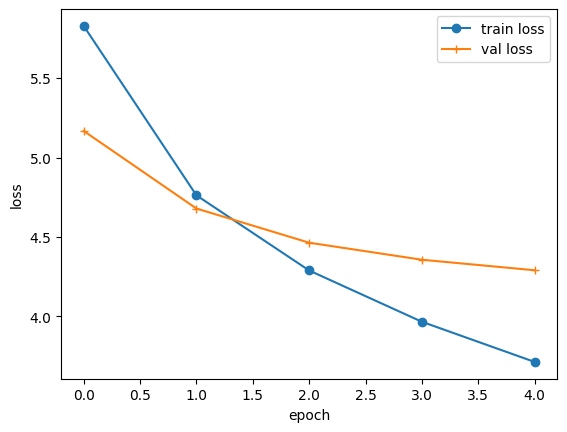

In [22]:
optimizer = torch.optim.Adam(model2.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
train_losses = []
val_losses = []
for epoch in range(1, N_EPOCHS + 1):
    train_loss = train_epoch(model2, train_loader, optimizer, criterion)
    val_loss = evaluate(model2, val_loader, criterion)
    print(f"Epoch: {epoch}, Train loss: {train_loss:.4f}, Val loss: {val_loss:.4f}")
    train_losses.append(train_loss)
    val_losses.append(val_loss)
plt.plot(train_losses, marker='o', label="train loss")
plt.plot(val_losses, marker='+', label="val loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

In [23]:
torch.save(model2.state_dict(), "model2.pt")
print("model saved")

model saved


In [ ]:
test_loss = evaluate(model2, test_loader, criterion)

@torch.no_grad()
def calculate_token_accuracy(model, loader):
    model.eval()
    matching = 0.0
    total = 0.0
    for srcs, tgts, src_masks in tqdm(loader, desc="token accuracy calculation"):
        srcs, tgts, src_masks = srcs.to(DEVICE), tgts.to(DEVICE), src_masks.to(DEVICE)
        out = model(srcs, tgts, src_masks)
        out = out[:, :-1]
        true_label = tgts[:, 1:]
        out = out.argmax(-1)
        # print(out.shape)
        # # print(out)
        # print(true_label.shape)
        # # print(true_label)
        # print(true_label.dtype)
        # print(out.dtype)
        matching += ((out == true_label) & (true_label != PAD_IDX)).sum().item()
        total += (true_label != PAD_IDX).sum().item()
    return matching / total if total else 0.0

token_acc = calculate_token_accuracy(model2, test_loader)
print(f"test loss: {test_loss:.4f}, token acc: {token_acc*100:.2f}%")

token accuracy calculation: 100%|██████████| 16/16 [00:00<00:00, 24.95it/s]

test loss: 4.1776, token acc: 30.22%


In [42]:
test_batch = next(iter(test_loader))
src, tgt, src_mask = test_batch
src, tgt, src_mask = src.to(DEVICE), tgt.to(DEVICE), src_mask.to(DEVICE)
with torch.no_grad():
    enc_out, hidden = model2.encoder(src)
    hidden = hidden.squeeze(0)
    token = tgt[:, 0]   # (B,)
    pred, hidden, alpha = model2.decoder.forward_step(token, hidden, enc_out, src_mask)
    print(alpha.shape)
    # print(alpha)
    print(alpha.sum(dim=1))
    row_max, _ = alpha.max(dim=1)
    row_min, _ = alpha.min(dim=1)
    print(row_max)
    print(row_min)
    print(row_max.sum())
    print(row_min.sum())


torch.Size([64, 30])
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000], device='cuda:0')
tensor([0.4219, 0.8134, 0.6800, 0.7695, 0.7847, 0.4730, 0.4218, 0.3544, 0.9777,
        0.3751, 0.6886, 0.5623, 0.6752, 0.4215, 0.7531, 0.7826, 0.6342, 0.3257,
        0.5446, 0.9804, 0.8457, 0.8479, 0.8694, 0.7509, 0.7073, 0.3641, 0.6567,
        0.4454, 0.5707, 0.4727, 0.7738, 0.8170, 0.7989, 0.7227, 0.9307, 0.8819,
        0.8396, 0.4702, 0.6930, 0.8164, 0.7532, 0.4653, 0.8793, 0

---
## Task 3: Visualising Word–Word Relationships

In [78]:
# Task 3 — YOUR CODE HERE
def fetch_attention_matrix(index):
    src_el = (src[index]).unsqueeze(0)
    tgt_el = (tgt[index]).unsqueeze(0)
    src_mask_el = (src_mask[index]).unsqueeze(0)
    # src_el.shape, tgt_el.shape, src_mask_el.shape
    with torch.no_grad():
        _, T = tgt_el.shape
        _, S = src_el.shape
        enc_out, hidden = model2.encoder(src_el)
        hidden = hidden.squeeze(0)
        attention_matrix = torch.zeros(T, S).to(DEVICE)
        # Step 3: First input token is <sos> — tgt[:, 0]
        token = tgt_el[:, 0]   # (B,)
        # Step 4: Decode step by step
        for t in range(1, T):
            # Call decoder one step at a time
            # Hint: self.decoder.forward_step(token, hidden, enc_out, src_mask)
            # Store prediction in outputs[:, t]
            # Next input token = model's own prediction (argmax)
            pred, hidden, alpha = model2.decoder.forward_step(token, hidden, enc_out, src_mask_el)
            alpha.squeeze(0)
            # print(attention_matrix[t].shape)
            attention_matrix[t] = alpha
            token           = pred.argmax(1)
    return attention_matrix
AM1 = fetch_attention_matrix(0)
AM2 = fetch_attention_matrix(1)
AM3 = fetch_attention_matrix(2)

In [63]:
M01 = data_generator.__getitem__(0)
M02 = data_generator.__getitem__(1)
M03 = data_generator.__getitem__(2)
print(M01)

(tensor([   1,    4,    9,    6,   21,   85,   66, 2593,   20,  120,    5,    2,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0]), tensor([  1,   5,  13,  11,   6, 198, 124,   9,  15,  94,   3,   4,   2,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0]), tensor([ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False, False]))


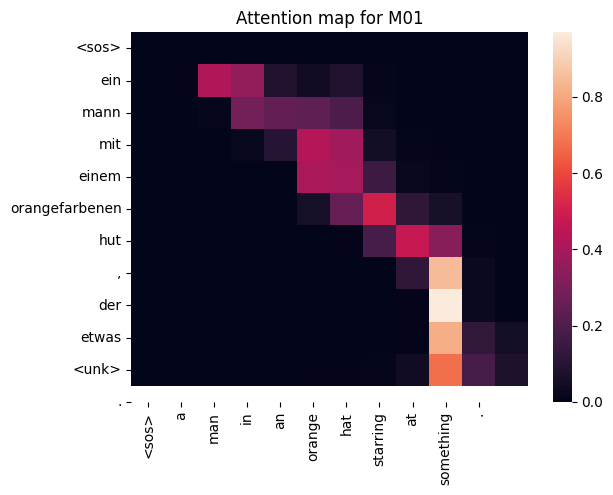

In [80]:
import seaborn as sns
src1, tgt1, _ = M01
for i in range(MAX_LEN):
    if src1[i] == EOS_IDX:
        j = i
    if tgt1[i] == EOS_IDX:
        k = i
sns.heatmap(AM1[:j, :k].detach().cpu().numpy(), yticklabels=tgt_vocab.decode_numbers(tgt1.detach().cpu().numpy())[:k], xticklabels=src_vocab.decode_numbers(src1.detach().cpu().numpy())[:j])
plt.title("Attention map for M01")
plt.show()

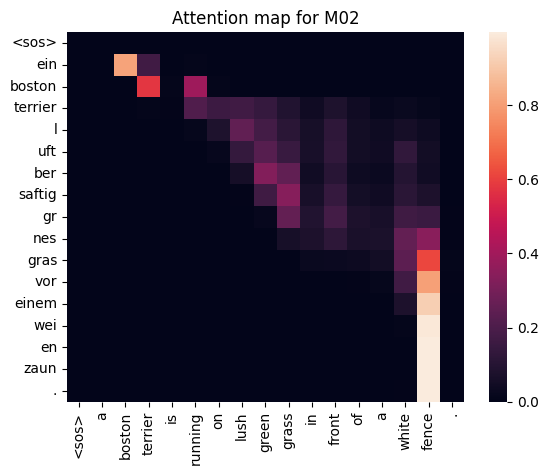

In [81]:
src2, tgt2, _ = M02
for i in range(MAX_LEN):
    if src2[i] == EOS_IDX:
        j = i
    if tgt2[i] == EOS_IDX:
        k = i
sns.heatmap(AM2[:j, :k].detach().cpu().numpy(), yticklabels=tgt_vocab.decode_numbers(tgt2.detach().cpu().numpy())[:k], xticklabels=src_vocab.decode_numbers(src2.detach().cpu().numpy())[:j])
plt.title("Attention map for M02")
plt.show()

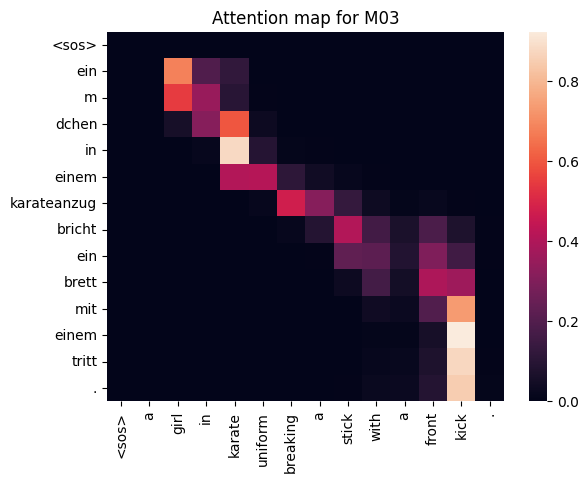

In [82]:
src3, tgt3, _ = M03
for i in range(MAX_LEN):
    if src3[i] == EOS_IDX:
        j = i
    if tgt3[i] == EOS_IDX:
        k = i
sns.heatmap(AM3[:j, :k].detach().cpu().numpy(), yticklabels=tgt_vocab.decode_numbers(tgt3.detach().cpu().numpy())[:k], xticklabels=src_vocab.decode_numbers(src3.detach().cpu().numpy())[:j])
plt.title("Attention map for M03")
plt.show()

---
## Task 4: Scaled Dot-Product Attention

In [28]:
# Task 4 — YOUR CODE HERE

---
## Task 5: Multi-Head Attention

In [29]:
# Task 5 — YOUR CODE HERE

---
## Task 6: Comparison and Analysis

In [30]:
# Task 6 — YOUR CODE HERE